# 04 個人權重（方法一）：重視家庭的人，家庭滿意度對幸福的影響比較大嗎？

**原始假設**：每個人對工作與家庭的重視程度不同，所以應該先算出每個人的權重，再乘上工作與家庭的原始分數去預測幸福。

**把假設寫成可檢驗的模型**：如果「重視程度」I 真的改變權重，那麼家庭滿意度的斜率應該隨 I 上升、工作滿意度的斜率隨 I 下降：

$$\text{幸福}_i = (a_F + b_F I_i)\,\text{家庭}_i + (a_J + b_J I_i)\,\text{工作}_i + \gamma'\text{控制}_i + \varepsilon_i$$

- b_F > 0、b_J < 0 → 假設成立，而且個人權重 = 由資料估出的 a + b·I，不是我們自己訂的。
- 這就是「交互作用（調節）模型」，心理學稱為「重要性加權」的直接檢驗（Wu & Yao, 2006; Rohrer & Schmukle, 2018）。

**重視程度的三種量法**
1. **RR2022 家庭價值重要性 8 題**（直接問「對您自己有多重要」，全樣本約 5,500 人）← 最貼近「權重」概念，主分析
2. **RR2020 家庭導向 FO 9 題**（婚姻態度＋傳統分工，全樣本約 5,500 人）
3. **「丈夫賺錢養家、太太照顧家庭」單題**（2020/2022/2024 三波都有）

**控制人生階段**：重視家庭的人通常年紀較大、已婚、有小孩。若不控制「年齡、婚姻、子女、性別 × 滿意度」的交互作用，重要性的效果可能只是人生階段的效果。

In [1]:
import numpy as np, pandas as pd
import statsmodels.formula.api as smf
from sklearn.model_selection import KFold
from psfd_utils import *
plt = setup_plot()
main = pd.read_csv(DERIVED / "main_2020_2024.csv", low_memory=False)
sub = pd.read_csv(DERIVED / "importance_subscales.csv")
main = main.merge(sub, on=["pid", "year"], how="left")
emp = main[main.employed == 1].dropna(subset=["swb", "jobsat", "famsat", "econsat", "health", "age", "female"]).copy()
# 在每一波內標準化，讓係數 = 標準化權重
for c in ["swb", "jobsat", "famsat", "econsat", "health"]:
    emp[c + "_z"] = emp.groupby("year")[c].transform(z)
emp["age_c"] = (emp.age - 45) / 10
emp["married_f"] = emp.married.fillna(0)
emp["kids_f"] = emp.has_kids.fillna(0)
CTRL = "econsat_z + health_z + age + I(age**2) + female + web"
LIFE = "(jobsat_z + famsat_z):(age_c + female + married_f + kids_f)"


def fit(f, d):
    m0 = smf.ols(f, d).fit()
    return smf.ols(f, d).fit(cov_type="cluster", cov_kwds={"groups": d.loc[m0.model.data.row_labels, "pid"]})


def inter_table(m, mod):
    keys = [k for k in m.params.index if (":" in k and mod in k and ("jobsat" in k or "famsat" in k) and k.count(":") == 1)]
    t = pd.DataFrame({"coef": m.params[keys], "se": m.bse[keys], "p": m.pvalues[keys]})
    return t.round(4)

## 1. RR2022：家庭價值重要性 × 滿意度

In [2]:
d22 = emp[(emp.year == 2022)].dropna(subset=["fam_importance"]).copy()
for c in ["fam_importance", "imp_marriage", "imp_support"]:
    d22[c + "_z"] = z(d22[c])
print("N =", len(d22))
res = {}
for mod in ["fam_importance_z", "imp_marriage_z", "imp_support_z"]:
    m_a = fit(f"swb_z ~ (jobsat_z + famsat_z) * {mod} + {CTRL}", d22)
    m_b = fit(f"swb_z ~ (jobsat_z + famsat_z) * {mod} + {LIFE} + {CTRL}", d22)
    res[mod] = (m_a, m_b)
    print(f"\n=== {mod}（左：只控制基本變項；右：再控制人生階段 × 滿意度）")
    print(pd.concat([inter_table(m_a, mod), inter_table(m_b, mod)], axis=1, keys=["基本", "+人生階段"]))

N = 4432

=== fam_importance_z（左：只控制基本變項；右：再控制人生階段 × 滿意度）
                               基本                   +人生階段                
                             coef      se       p    coef      se       p
jobsat_z:fam_importance_z -0.0314  0.0137  0.0222 -0.0273  0.0155  0.0783
famsat_z:fam_importance_z  0.0331  0.0152  0.0291  0.0253  0.0168  0.1312



=== imp_marriage_z（左：只控制基本變項；右：再控制人生階段 × 滿意度）
                             基本                   +人生階段                
                           coef      se       p    coef      se       p
jobsat_z:imp_marriage_z -0.0358  0.0138  0.0096 -0.0344  0.0164  0.0359
famsat_z:imp_marriage_z  0.0390  0.0154  0.0112  0.0323  0.0184  0.0783

=== imp_support_z（左：只控制基本變項；右：再控制人生階段 × 滿意度）
                            基本                   +人生階段                
                          coef      se       p    coef      se       p
jobsat_z:imp_support_z -0.0110  0.0135  0.4161 -0.0079  0.0140  0.5712
famsat_z:imp_support_z  0.0125  0.0141  0.3780  0.0081  0.0143  0.5685


In [3]:
m_imp = res["fam_importance_z"][1]
coef_table(m_imp, ["jobsat_z", "famsat_z", "fam_importance_z", "jobsat_z:fam_importance_z", "famsat_z:fam_importance_z"])

,coef,se,p,ci_low,ci_high
jobsat_z,0.2253,0.0307,0.0000,0.1650,0.2855
famsat_z,0.2586,0.0314,0.0000,0.1970,0.3201
fam_importance_z,0.0728,0.0129,0.0000,0.0474,0.0981
jobsat_z:fam_importance_z,-0.0273,0.0155,0.0783,-0.0577,0.0031
famsat_z:fam_importance_z,0.0253,0.0168,0.1312,-0.0076,0.0582


### 1.1 把交互作用換算成「個人權重」：重要性低、中、高的人，家庭權重 w 是多少？

In [4]:
def implied_weights(m, mod, levels=(-1.28, 0, 1.28)):
    out = []
    for q, lv in zip(["第 10 百分位", "中位數", "第 90 百分位"], levels):
        bF = m.params["famsat_z"] + m.params[f"famsat_z:{mod}"] * lv
        bJ = m.params["jobsat_z"] + m.params[f"jobsat_z:{mod}"] * lv
        out.append(dict(重視程度=q, 家庭斜率=bF, 工作斜率=bJ, 家庭權重w=bF / (bF + bJ)))
    return pd.DataFrame(out).round(3)

implied_weights(m_imp, "fam_importance_z")

,重視程度,家庭斜率,工作斜率,家庭權重w
0,第 10 百分位,0.226,0.260,0.465
1,中位數,0.259,0.225,0.534
2,第 90 百分位,0.291,0.190,0.605


### 1.2 視覺化：依重要性分成 5 組，各組分別估家庭與工作的斜率

領域,家庭,工作
組,,
1,0.216,0.246
2,0.313,0.237
3,0.319,0.177
4,0.310,0.189
5,0.294,0.140


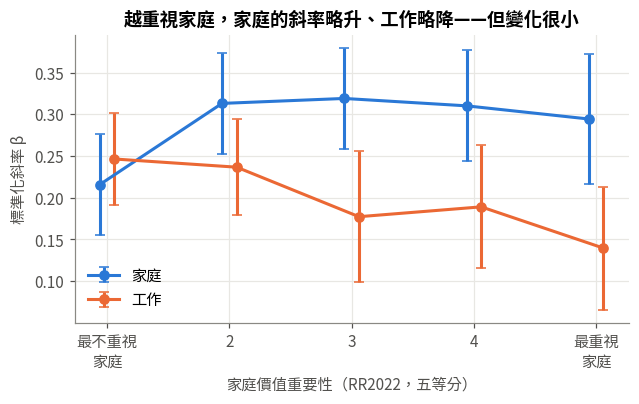

In [5]:
d22["imp_q"] = pd.qcut(d22.fam_importance, 5, labels=False, duplicates="drop") + 1
rows = []
for q, g in d22.groupby("imp_q"):
    m = smf.ols(f"swb_z ~ jobsat_z + famsat_z + {CTRL}", g).fit(cov_type="HC1")
    for v, nm in [("famsat_z", "家庭"), ("jobsat_z", "工作")]:
        ci = m.conf_int().loc[v]
        rows.append(dict(組=q, 領域=nm, beta=m.params[v], lo=ci[0], hi=ci[1], N=len(g), 重要性平均=g.fam_importance.mean()))
qt = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(6.5, 3.4))
for nm, col, off in [("家庭", C_FAMILY, -0.06), ("工作", C_WORK, 0.06)]:
    t = qt[qt.領域 == nm]
    ax.errorbar(t.組 + off, t.beta, yerr=[t.beta - t.lo, t.hi - t.beta], marker="o", color=col, label=nm, capsize=3)
ax.set_xticks([1, 2, 3, 4, 5], ["最不重視\n家庭", "2", "3", "4", "最重視\n家庭"])
ax.set_ylabel("標準化斜率 β"); ax.set_xlabel("家庭價值重要性（RR2022，五等分）"); ax.legend()
ax.set_title("越重視家庭，家庭的斜率略升、工作略降——但變化很小")
savefig(fig, "fig04_importance_quintiles")
qt.pivot(index="組", columns="領域", values="beta").round(3)

## 2. RR2020：家庭導向（FO）× 滿意度

In [6]:
d20 = emp[(emp.year == 2020)].dropna(subset=["fo"]).copy()
d20["fo_z"] = z(d20.fo)
print("N =", len(d20))
m20a = fit(f"swb_z ~ (jobsat_z + famsat_z) * fo_z + {CTRL}", d20)
m20b = fit(f"swb_z ~ (jobsat_z + famsat_z) * fo_z + {LIFE} + {CTRL}", d20)
print(pd.concat([inter_table(m20a, "fo_z"), inter_table(m20b, "fo_z")], axis=1, keys=["基本", "+人生階段"]))
implied_weights(m20b, "fo_z")

N = 4289
                   基本                   +人生階段                
                 coef      se       p    coef      se       p
jobsat_z:fo_z  0.0001  0.0127  0.9916  0.0050  0.0139  0.7198
famsat_z:fo_z -0.0001  0.0128  0.9929 -0.0089  0.0139  0.5202


,重視程度,家庭斜率,工作斜率,家庭權重w
0,第 10 百分位,0.251,0.220,0.533
1,中位數,0.240,0.226,0.514
2,第 90 百分位,0.228,0.233,0.495


## 3. 三波都有的單題：「丈夫賺錢養家、太太照顧家庭」× 滿意度（2020–2024 合併）

In [7]:
dp = emp.dropna(subset=["breadwinner"]).copy()
dp["bw_z"] = dp.groupby("year").breadwinner.transform(z)
mbw = fit(f"swb_z ~ (jobsat_z + famsat_z) * bw_z + {LIFE} + {CTRL} + C(year)", dp)
print("N =", len(dp))
inter_table(mbw, "bw_z")

N = 13040


,coef,se,p
jobsat_z:bw_z,-0.0135,0.0092,0.1436
famsat_z:bw_z,-0.0020,0.0095,0.8342


## 4. 對照組：人生階段本身會不會改變權重？（2020–2024 合併）

若權重真的因人而異，那「是誰」在改變權重？我們同時放入年齡、性別、婚姻、子女與滿意度的交互作用。

In [8]:
mlife = fit(f"swb_z ~ jobsat_z + famsat_z + {LIFE} + {CTRL} + C(year)", emp)
t = coef_table(mlife)
life_tab = t[t.index.str.contains(":")]
life_tab

,coef,se,p,ci_low,ci_high
jobsat_z:age_c,0.0026,0.0103,0.8015,-0.0177,0.0229
jobsat_z:female,-0.0151,0.0180,0.4005,-0.0503,0.0201
jobsat_z:married_f,0.0189,0.0244,0.4381,-0.0289,0.0668
jobsat_z:kids_f,-0.0760,0.0261,0.0036,-0.1271,-0.0248
famsat_z:age_c,0.0101,0.0117,0.3865,-0.0128,0.0330
famsat_z:female,0.0310,0.0188,0.0984,-0.0058,0.0678
famsat_z:married_f,-0.0278,0.0229,0.2246,-0.0725,0.0170
famsat_z:kids_f,0.0832,0.0250,0.0009,0.0342,0.1323


## 5. 關鍵檢驗：個人化權重能不能「預測得更準」？

統計顯著 ≠ 有用。我們用 5 折交叉驗證，比較下列模型在**沒看過的資料**上的 R²（RR2022，有工作且有重要性題者）：

| 模型 | 權重怎麼來 |
|---|---|
| M0 等權重 | 工作、家庭各 0.5 |
| M_原構想 | 依重要性百分位直接當家庭權重 w，工作權重 1−w（原始計畫的公式） |
| M1 全體權重 | 迴歸估計，每人相同 |
| M2 重要性調節 | 方法一：權重隨重要性變 |
| M3 人生階段調節 | 權重隨年齡、性別、婚姻、子女變 |
| M4 兩者皆有 | |

所有模型都含相同的控制變數（經濟滿意度、健康、年齡、性別、填答模式）。

In [9]:
def design(d, kind):
    X = pd.DataFrame(index=d.index)
    X["econ"] = d.econsat_z; X["health"] = d.health_z; X["age"] = d.age; X["age2"] = d.age ** 2
    X["female"] = d.female; X["web"] = d.web
    w = d.fam_importance.rank(pct=True)
    if kind == "M0 等權重":
        X["score"] = 0.5 * d.famsat_z + 0.5 * d.jobsat_z
    elif kind == "M_原構想（重要性百分位當權重）":
        X["score"] = w * d.famsat_z + (1 - w) * d.jobsat_z
    else:
        X["job"] = d.jobsat_z; X["fam"] = d.famsat_z
    if kind in ("M2 重要性調節", "M4 兩者皆有"):
        X["imp"] = d.imp_z; X["job_imp"] = d.jobsat_z * d.imp_z; X["fam_imp"] = d.famsat_z * d.imp_z
    if kind in ("M3 人生階段調節", "M4 兩者皆有"):
        for v in ["age_c", "female", "married_f", "kids_f"]:
            X[f"job_{v}"] = d.jobsat_z * d[v]; X[f"fam_{v}"] = d.famsat_z * d[v]; X[v] = d[v]
    return X.values, d.swb_z.values


d22["imp_z"] = z(d22.fam_importance)
kinds = ["M0 等權重", "M_原構想（重要性百分位當權重）", "M1 全體權重", "M2 重要性調節", "M3 人生階段調節", "M4 兩者皆有"]
cvres = []
for k in kinds:
    X, y = design(d22, k)
    r = [cv_r2(X, y, k=5, seed=s)[0] for s in range(10)]      # 重複 10 次不同切法
    cvres.append(dict(模型=k, CV_R2=np.mean(r), 標準差=np.std(r)))
cvtab = pd.DataFrame(cvres)
cvtab["相對 M1 的差"] = cvtab.CV_R2 - cvtab.loc[cvtab.模型 == "M1 全體權重", "CV_R2"].values[0]
cvtab.round(4)

,模型,CV_R2,標準差,相對 M1 的差
0,M0 等權重,0.3940,0.0009,-0.0023
1,M_原構想（重要性百分位當權重）,0.3814,0.0009,-0.0148
2,M1 全體權重,0.3963,0.0009,0.0000
3,M2 重要性調節,0.4010,0.0010,0.0047
4,M3 人生階段調節,0.3978,0.0013,0.0016
5,M4 兩者皆有,0.4006,0.0014,0.0043


PosixPath('figures/fig04b_cv_models.png')

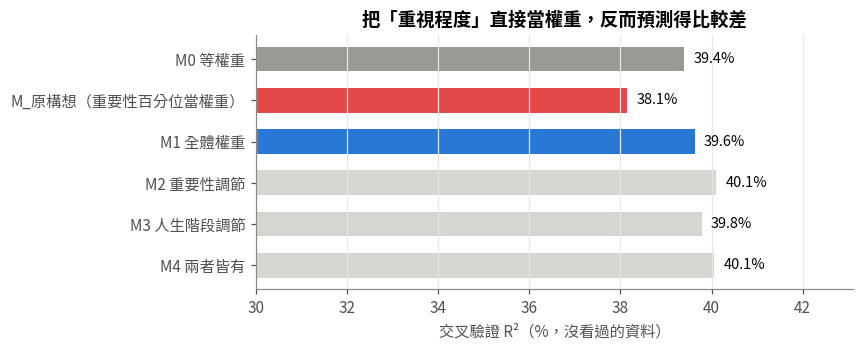

In [10]:
fig, ax = plt.subplots(figsize=(7, 3.0))
cols = [PALETTE["grey"], PALETTE["red"], PALETTE["blue"], PALETTE["grey_light"], PALETTE["grey_light"], PALETTE["grey_light"]]
ax.barh(cvtab.模型, cvtab.CV_R2 * 100, color=cols, height=0.6)
for i, v in enumerate(cvtab.CV_R2 * 100): ax.text(v + 0.2, i, f"{v:.1f}%", va="center", fontsize=9.5)
ax.invert_yaxis(); ax.set_xlim(30, cvtab.CV_R2.max() * 100 + 3); ax.set_xlabel("交叉驗證 R²（%，沒看過的資料）")
ax.grid(axis="y", visible=False)
ax.set_title("把「重視程度」直接當權重，反而預測得比較差")
savefig(fig, "fig04b_cv_models")

## 6. 跨時間驗證：2022 的重要性，能不能預測同一個人 2024 年的權重？

交叉驗證仍是同一年的資料。更嚴格的做法：用 2022 年估出的模型（含重要性交互作用），套到同一批人 2024 年的工作/家庭滿意度上，預測他們 2024 年的幸福——重要性是兩年前量的，2024 的資料模型完全沒看過。

In [11]:
imp_by_pid = d22.set_index("pid").fam_importance
d24 = emp[emp.year == 2024].copy()
d24["fam_importance"] = d24.pid.map(imp_by_pid)
d24 = d24.dropna(subset=["fam_importance"])
d24["imp_z"] = (d24.fam_importance - d22.fam_importance.mean()) / d22.fam_importance.std()
print("2024 年有 2022 重要性的有工作者：", len(d24))
from sklearn.linear_model import LinearRegression
rows = []
for k in kinds:
    Xtr, ytr = design(d22, k)
    Xte, yte = design(d24, k)
    mdl = LinearRegression().fit(Xtr, ytr)
    p = mdl.predict(Xte)
    rows.append(dict(模型=k, 預測2024_R2=1 - ((yte - p) ** 2).sum() / ((yte - yte.mean()) ** 2).sum()))
oot = pd.DataFrame(rows)
oot.to_csv(DERIVED / "oot_2024_models.csv", index=False)
oot.round(4)

2024 年有 2022 重要性的有工作者： 3815


,模型,預測2024_R2
0,M0 等權重,0.3898
1,M_原構想（重要性百分位當權重）,0.3745
2,M1 全體權重,0.3928
3,M2 重要性調節,0.3931
4,M3 人生階段調節,0.3963
5,M4 兩者皆有,0.3961


## 7. 原構想公式在 RR2020（用 FO 當權重）也一樣嗎？

In [12]:
d20["w"] = d20.fo.rank(pct=True)
for nm, score in [("等權重", 0.5 * d20.famsat_z + 0.5 * d20.jobsat_z),
                  ("FO 百分位當權重", d20.w * d20.famsat_z + (1 - d20.w) * d20.jobsat_z),
                  ("反過來（FO 越高越重工作）", (1 - d20.w) * d20.famsat_z + d20.w * d20.jobsat_z)]:
    print(f"{nm:20s} 與幸福的相關 r = {np.corrcoef(score, d20.swb_z)[0,1]:.4f}")

等權重                  與幸福的相關 r = 0.5467
FO 百分位當權重            與幸福的相關 r = 0.5048
反過來（FO 越高越重工作）       與幸福的相關 r = 0.5060


In [13]:
cvtab.to_csv(DERIVED / "cv_models_2022.csv", index=False)
qt.to_csv(DERIVED / "importance_quintile_slopes.csv", index=False)
inter_out = pd.concat([inter_table(m_imp, "fam_importance_z").assign(來源="2022 重要性"),
                       inter_table(m20b, "fo_z").assign(來源="2020 FO"),
                       inter_table(mbw, "bw_z").assign(來源="傳統分工單題")])
inter_out.to_csv(DERIVED / "moderation_results.csv")
inter_out

,coef,se,p,來源
jobsat_z:fam_importance_z,-0.0273,0.0155,0.0783,2022 重要性
famsat_z:fam_importance_z,0.0253,0.0168,0.1312,2022 重要性
jobsat_z:fo_z,0.0050,0.0139,0.7198,2020 FO
famsat_z:fo_z,-0.0089,0.0139,0.5202,2020 FO
jobsat_z:bw_z,-0.0135,0.0092,0.1436,傳統分工單題
famsat_z:bw_z,-0.0020,0.0095,0.8342,傳統分工單題
